# LeNet-5 Neural Network for MNIST


### Options


In [39]:
batch_size = 20
EPOCHS = 100

### Setup our model


In [40]:
from torch import nn
import torch

import brevitas.nn as qnn
from brevitas.core.quant import QuantType
import torch.nn.functional as F


import brevitas.nn as qnn
from brevitas.quant import Int8WeightPerTensorFixedPoint, Int8ActPerTensorFixedPoint, Int8BiasPerTensorFloatInternalScaling, Int8BiasPerTensorFixedPointInternalScaling


class QuantLeNet(nn.Module):
    
    def __init__(self):
        super(QuantLeNet, self).__init__()
        self.quant_inp = qnn.QuantIdentity(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True)
        self.conv1 = qnn.QuantConv2d(1, 6, 5, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8, bias_quant=Int8BiasPerTensorFixedPointInternalScaling)
        self.relu1 = qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True)
        self.conv2 = qnn.QuantConv2d(6, 16, 5, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8, bias_quant=Int8BiasPerTensorFixedPointInternalScaling)
        self.relu2 = qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True)
        self.fc1   = qnn.QuantLinear(16*5*5, 120, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8, bias_quant=Int8BiasPerTensorFixedPointInternalScaling)
        self.fc2   = qnn.QuantLinear(120, 84, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8, bias_quant=Int8BiasPerTensorFixedPointInternalScaling)
        self.fc3   = qnn.QuantLinear(84, 10, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8, bias_quant=Int8BiasPerTensorFixedPointInternalScaling)

    def forward(self, x):
        out = self.quant_inp(x)
        out = self.relu1(self.conv1(out))
        out = F.max_pool2d(out, 2)
        out = self.relu2(self.conv2(out))
        out = F.max_pool2d(out, 2)
        out = out.reshape(out.shape[0], -1)
        out = self.fc1(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

model = QuantLeNet()
print(model)

QuantLeNet(
  (quant_inp): QuantIdentity(
    (input_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
    )
    (act_quant): ActQuantProxyFromInjector(
      (_zero_hw_sentinel): StatelessBuffer()
      (fused_activation_quant_proxy): FusedActivationQuantProxy(
        (activation_impl): Identity()
        (tensor_quant): RescalingIntQuant(
          (int_quant): IntQuant(
            (float_to_int_impl): RoundSte()
            (tensor_clamp_impl): TensorClamp()
            (delay_wrapper): DelayWrapper(
              (delay_impl): _NoDelay()
            )
            (input_view_impl): Identity()
          )
          (scaling_impl): ParameterFromRuntimeStatsScaling(
            (stats_input_view_shape_impl): OverTensorView()
            (stats): _Stats(
              (stats_impl): AbsPercentile()
            )
            (restrict_scaling_impl): PowerOfTwoRestrictValue(
              (float_to_int_impl): CeilSte()
              (power_of_two): PowerOfT

In [41]:
import torch

use_gpu = torch.cuda.is_available()
use_gpu = False # Dataset so small that CPU is faster
if use_gpu:
    device = torch.device("cuda")
    model = model.cuda()
    print("USE GPU")
else:
    print("USE CPU")

USE CPU


### Setting up the data


In [42]:
import torch
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose(
    [transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
    transforms.Pad(padding=[2,2])])


training_set = torchvision.datasets.MNIST('./data', train=True, transform=transform, download=True)
validation_set = torchvision.datasets.MNIST('./data', train=False, transform=transform, download=True)

training_loader = torch.utils.data.DataLoader(training_set, batch_size=4, shuffle=True)
validation_loader = torch.utils.data.DataLoader(validation_set, batch_size=4, shuffle=False)

classes = ('0', '1', '2', '3', '4',
        '5', '6', '7', '8', '9')

# Report split sizes
print('Training set has {} instances'.format(len(training_set)))
print('Validation set has {} instances'.format(len(validation_set)))


Training set has 60000 instances
Validation set has 10000 instances


## Exporting of Data

In [43]:
import numpy as np

x_val = []
y_val = []

x_train = []
y_train = []

for (x, y) in validation_set:
    x_val.append(x.detach().numpy())
    tmp = np.full(shape=(10, ), fill_value=0)
    tmp[y] = 1
    y_val.append(tmp)

for (x, y) in training_set:
    x_train.append(x.detach().numpy())
    tmp = np.full(shape=(10, ), fill_value=0)
    tmp[y] = 1
    y_train.append(tmp)

x_val = np.array(x_val, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
x_train = np.array(x_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

print(np.shape(x_val), np.shape(y_val))
print(np.shape(x_train), np.shape(y_val))

np.save("./export/mnist/x_test.npy", x_val)
np.save("./export/mnist/y_test.npy", y_val)
np.save("./export/mnist/x_train.npy", x_train)
np.save("./export/mnist/y_train.npy", y_train)

(10000, 1, 32, 32) (10000, 10)
(60000, 1, 32, 32) (10000, 10)


## Visualization of Data

7  8  1  1


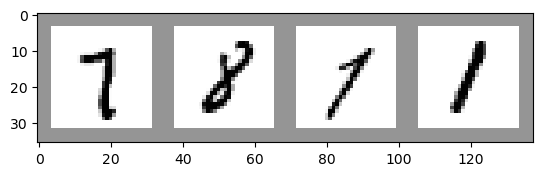

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Helper function for inline image display
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

dataiter = iter(training_loader)
images, labels = next(dataiter)

# Create a grid from the images and show them
img_grid = torchvision.utils.make_grid(images)
matplotlib_imshow(img_grid, one_channel=True)
print('  '.join(classes[labels[j]] for j in range(4)))

## Training

In [45]:
from torch.autograd import Variable
import datetime as d
from torch.utils.tensorboard import SummaryWriter

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

def train_one_epoch(epoch_index, tb_writer):
    running_loss = 0.
    last_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for i, data in enumerate(training_loader):
        # Every data instance is an input + label pair
        inputs, labels = data
        inputs = inputs.to("cuda:0" if use_gpu else "cpu")
        labels = labels.to("cuda:0" if use_gpu else "cpu")

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = loss_fn(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()
        if i % 1000 == 999:
            last_loss = running_loss / 1000 # loss per batch
            print('  batch {} loss: {}'.format(i + 1, last_loss))
            tb_x = epoch_index * len(training_loader) + i + 1
            tb_writer.add_scalar('Loss/train', last_loss, tb_x)
            running_loss = 0.

    return last_loss

# Initializing in a separate cell so we can easily add more epochs to the same run
timestamp = d.datetime.now().strftime('%Y%m%d_%H%M%S')
writer = SummaryWriter('runs/fashion_trainer_{}'.format(timestamp))
epoch_number = 0

best_vloss = 1_000_000.

for epoch in range(EPOCHS):
    print('EPOCH {}:'.format(epoch_number + 1))

    # Make sure gradient tracking is on, and do a pass over the data
    model.train(True)
    avg_loss = train_one_epoch(epoch_number, writer)


    running_vloss = 0.0
    # Set the model to evaluation mode, disabling dropout and using population
    # statistics for batch normalization.
    model.eval()

    # Disable gradient computation and reduce memory consumption.
    with torch.no_grad():
        for i, vdata in enumerate(validation_loader):
            vinputs, vlabels = vdata
            voutputs = model(vinputs)
            vloss = loss_fn(voutputs, vlabels)
            running_vloss += vloss

    avg_vloss = running_vloss / (i + 1)
    print('LOSS train {} valid {}'.format(avg_loss, avg_vloss))

    # Log the running loss averaged per batch
    # for both training and validation
    writer.add_scalars('Training vs. Validation Loss',
                    { 'Training' : avg_loss, 'Validation' : avg_vloss },
                    epoch_number + 1)
    writer.flush()

    # Track best performance, and save the model's state
    if avg_vloss < best_vloss:
        best_vloss = avg_vloss

    epoch_number += 1

EPOCH 1:
  batch 1000 loss: 2.283194262266159
  batch 2000 loss: 2.240567114830017
  batch 3000 loss: 2.1939635338783265
  batch 4000 loss: 2.1705998797416686
  batch 5000 loss: 2.1568315210342406
  batch 6000 loss: 2.1486419560909273
  batch 7000 loss: 2.1432154774665833
  batch 8000 loss: 2.136800127744675
  batch 9000 loss: 2.134848151445389
  batch 10000 loss: 2.1291840517520906
  batch 11000 loss: 2.073739252924919
  batch 12000 loss: 1.9935168424844742
  batch 13000 loss: 1.9747221124172212
  batch 14000 loss: 1.9602768219709397
  batch 15000 loss: 1.9497942625284195
LOSS train 1.9497942625284195 valid 1.9431090354919434
EPOCH 2:
  batch 1000 loss: 1.9431294053792953
  batch 2000 loss: 1.7510147960186004
  batch 3000 loss: 1.64919639980793
  batch 4000 loss: 1.6288909542560577
  batch 5000 loss: 1.4858033983707428
  batch 6000 loss: 1.2127563607096672
  batch 7000 loss: 1.1550409759879112
  batch 8000 loss: 1.0300576080977917
  batch 9000 loss: 0.7124937247633935
  batch 10000 lo

In [48]:
## This part is probably complettly unnecessary but I dont care

total_correct = 0
total_samples = 0

for images, labels in validation_loader:
        # Move the data to the device (CPU or GPU)

        # Forward pass
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

    # Update the running total of correct predictions and samples
    total_correct += (predicted == labels).sum().item()
    total_samples += labels.size(0)

# Calculate the accuracy for this epoch
accuracy = 100 * total_correct / total_samples
print(f'Accuracy = {accuracy:.2f}%')
print("Total misses: " + str(total_samples - total_correct) + " of " + str(total_samples))

Accuracy = 98.91%
Total misses: 109 of 10000


## Export model

In [49]:
import brevitas.onnx as bo

exported_model = bo.export_qonnx(model, args=torch.randn(1, 1, 32, 32), export_path="Lenet_qonnx.onnx", opset_version=13)